# AI 221 Machine Exercise 4
## 8x8 Handwritten Digits Visualization and Classification
#### by Quiel Andrew I. Quiwa 

In this machine exercise, we will be visualizing and classifying the 8x8 handwritten digits data from the ```load_digits``` dataset in sklearn. 

Particularly, we will be projecting all the X data into 2 dimensions using 6 dimensionality reduction techniques:

1. Local Linear Embedding (n_neighbors = 200, random_state = 0)
2. t-SNE (perplexity = 50, random_state = 0)
3. Isomap (n_neighbors = 200)
4. Laplacian Eigenmap (n_neighbors = 200)
5. Kernel PCA (kernel = ‘rbf’, gamma = 0.01)
6. PCA

For the KPCA and PCA items above, we will be reporting the cumulative percent variance plots to determine the number of principal components needed to retaing 95% CPV.

We will also be implementing three classification pipelines using the following methods:

1. Standard Scaler + KPCA + SVC
2. Standard Scaler + Linear Discriminant Analysis + SVC
3. Standard Scaler + SVC (no dimensionality reduction)

We will compare the accuracy and F1-scores of each of the pipelines above.

In [89]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.manifold import LocallyLinearEmbedding, TSNE, Isomap, SpectralEmbedding
from sklearn.decomposition import PCA, KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import classification_report
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import numpy as np


### Part 1. Projecting all the X data into 2 dimensions using 6 dimensionality reduction techniques

In [71]:
digits = datasets.load_digits()
print(digits.DESCR)

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

In [72]:
X = digits.data
y = digits.target

X_scaled = StandardScaler().fit_transform(X)

In [73]:
# For all plots, we will use the following parameters:

def plot_2d(X_2d, y, title):
    plt.figure(figsize=(6, 5))
    scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap='tab10', s=5)
    plt.colorbar(scatter, label="Digit Label")
    plt.title(title)
    plt.xlabel("Dimension 1")
    plt.ylabel("Dimension 2")
    plt.tight_layout()
    plt.show()

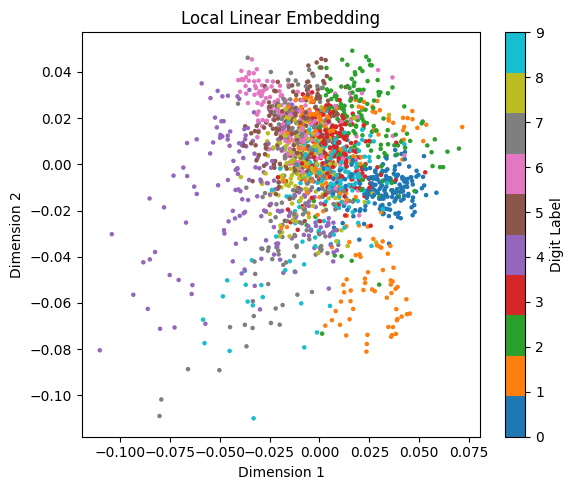

In [74]:
# Local Linear Embedding

local_linear_embedding = LocallyLinearEmbedding(n_components=2, n_neighbors=200,random_state=0)

X_local_linear_embedding = local_linear_embedding.fit_transform(X_scaled)

plot_2d(X_local_linear_embedding, y, "Local Linear Embedding")

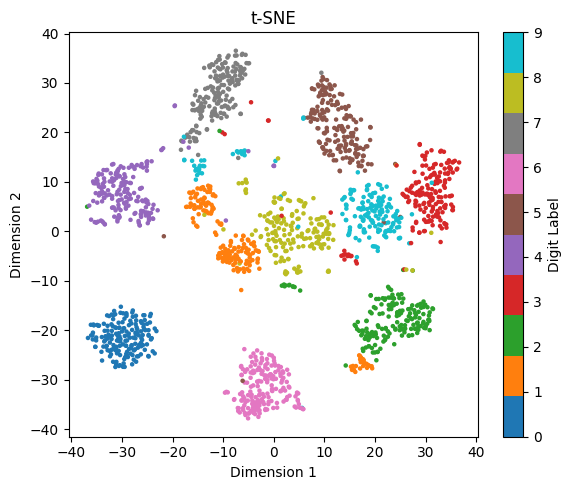

In [75]:
# t-SNE

tsne = TSNE(n_components=2, perplexity=50,random_state=0)

X_tsne = tsne.fit_transform(X_scaled)

plot_2d(X_tsne, y, "t-SNE")

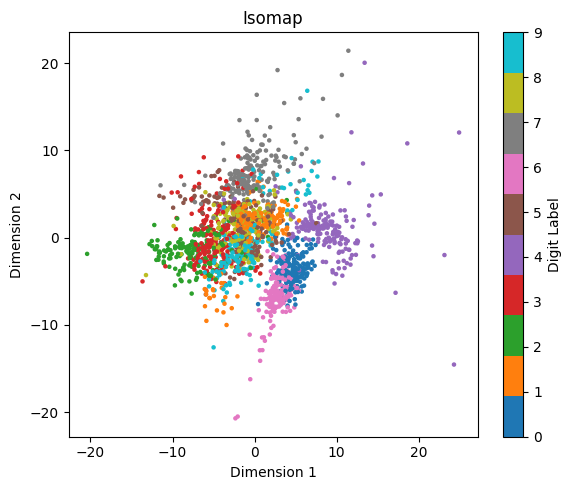

In [76]:
# isomap

isomap = Isomap(n_components=2, n_neighbors=200)

X_isomap = isomap.fit_transform(X_scaled)

plot_2d(X_isomap, y, "Isomap")

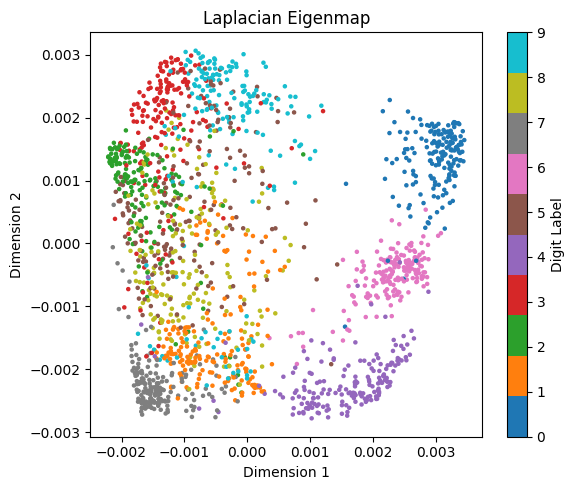

In [77]:
# Laplacian Eigenmap

laplacian_eigenmap = SpectralEmbedding(n_components=2, n_neighbors=200)

X_laplacian_eigenmap = laplacian_eigenmap.fit_transform(X_scaled)

plot_2d(X_laplacian_eigenmap, y, "Laplacian Eigenmap")

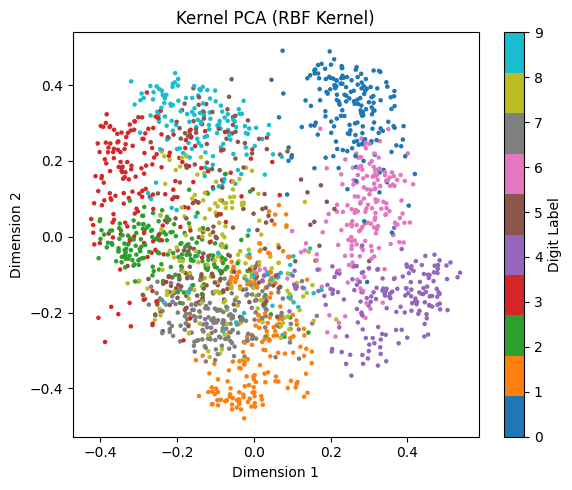

In [78]:
# Kernel PCA

kernel_pca = KernelPCA(n_components=2, kernel='rbf', gamma=0.01, random_state=0)
X_kernel_pca = kernel_pca.fit_transform(X_scaled)
plot_2d(X_kernel_pca, y, "Kernel PCA (RBF Kernel)")

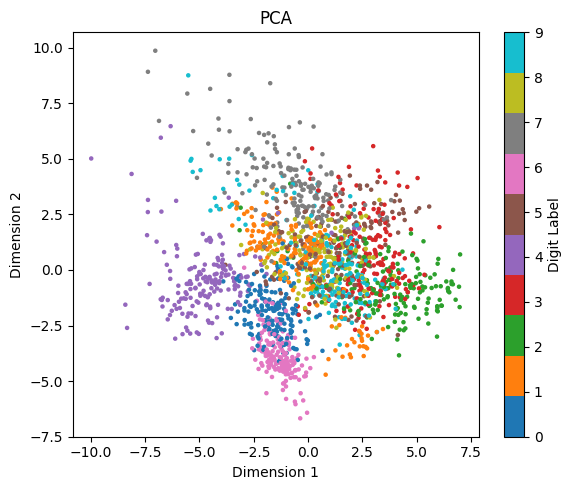

In [79]:
# PCA
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X_scaled)
plot_2d(X_pca, y, "PCA")

### Observations

1. t-SNE provided the clearest clusters, showing well-separated and compact groups for each digit. With the exception of a few points, all 10 digits are distinct and identifiable.

Recall that t-SNE computes a probability-based similarity $p_{ij}$ between all pairs of data points using a Gaussian distribution:

$$p_{j|i} = \frac{\exp\left(-\|x_i - x_j\|^2 \,/\, 2\sigma_i^2\right)}{\sum_{k \neq i} \exp\left(-\|x_i - x_k\|^2 \,/\, 2\sigma_i^2\right)}$$

Points that are close in the 64-dimensional feature space get a high probability of being neighbors, while far points get near-zero probability.

When projecting into 2D, t-SNE uses a Student's t-distribution with 1 degree of freedom instead of a Gaussian:

$$q_{ij} = \frac{\left(1 + \|y_i - y_j\|\right)^{-1}}{\sum_{k \neq l} \left(1 + \|y_k - y_l\|\right)^{-1}}$$

This distribution has heavier tails than a Gaussian, which means similar points are pulled strongly together and dissimilar points are pushed farther apart. This produces the clear and well-separated clusters visible in the plot.

2. Laplacian Eigenmap also produced a slightly clear set of clusters. There's a U-shaped structure with some digits occupying distinct regions. However, there's still some overlap in the left-middle part of the U-shape. 

3. Kernel PCA also had some slightly visible groups or regions, but the boundaries between groups are not very clear. We can observe significant overlaps especially on the left part. 

4. The rest of the models did not produce very clear clusters when observing the plots visually.

### Part 2. Cumulative Percent Variance
For both KPCA and PCA in the previous item, report the CPV plot and determine the number of principal components needed to retain 95% cumulative percent variance.

[ 12.0339161   21.5949705   30.03938539  36.5377933   41.39794818
  45.61206805  49.55415085  52.94353177  55.94175279  58.87375534
  61.6555608   64.23261589  66.50791921  68.73509895  70.90032838
  72.81449499  74.59004207  76.22811135  77.82457152  79.3137627
  80.66173227  81.93366364  83.09950099  84.15714759  85.13246353
  86.07702252  86.94003635  87.77667921  88.57437245  89.32084382
  90.04642598  90.73833722  91.39224576  92.03303833  92.62442244
  93.19558485  93.71922165  94.20102924  94.6547485   95.07791125
  95.48396432  95.88104913  96.23754243  96.57832961  96.90616495
  97.21719696  97.50577225  97.78226151  98.04143645  98.27591946
  98.49417632  98.69777395  98.89328638  99.07660488  99.24455127
  99.40578733  99.55355002  99.68866843  99.81376918  99.91746491
 100.         100.         100.         100.        ]


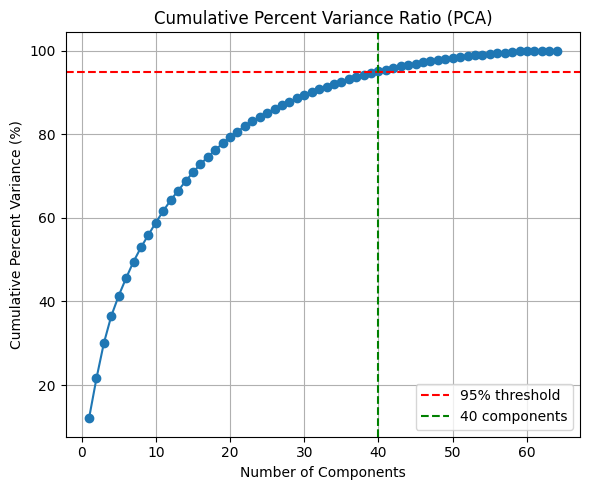

In [80]:
pca = PCA(n_components=64, random_state=0)
pca.fit(X_scaled)
cpv_pca = np.cumsum(pca.explained_variance_ratio_)*100
print(cpv_pca)

# plot cumulative percent variance for PCA
plt.figure(figsize=(6, 5))
# len(cpv_pca) is 64, so we plot from 1 to 64 + 1 because range is exclusive at the end
plt.plot(range(1, len(cpv_pca) + 1), cpv_pca, marker='o')

# Find the number of components needed to reach 95% cumulative variance
# n95 is the index of the first component where cpv_pca >= 95, plus 1 because of zero-based indexing
# enumerate gives us pairs of (index, value) for cpv_pca, and we check where the value is >= 95
n95 = next(i + 1 for i, v in enumerate(cpv_pca) if v >= 95)

# Add horizontal and vertical lines to indicate the 95% threshold and the corresponding number of components
plt.axhline(y=95, color='r', linestyle='--', label='95% threshold')
plt.axvline(x=n95, color='g', linestyle='--', label=f'{n95} components')

# Add text annotation to indicate the number of components needed for 95% variance
plt.legend()
plt.title("Cumulative Percent Variance Ratio (PCA)")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Percent Variance (%)")

# Add grid for better readability
plt.grid()

# Use tight_layout to prevent overlap of labels and title
plt.tight_layout()
plt.show()

[  9.97039167  19.25833504  26.64613905  32.47702907  37.83706727
  41.94140927  45.85562913  49.07912056  51.92001325  54.38699489
  56.74812497  58.91370562  60.84914613  62.66335084  64.2918766
  65.86997049  67.33773929  68.68579149  69.80906002  70.92554867
  71.9413469   72.93133265  73.86557409  74.77766436  75.62776987
  76.4444722   77.21997062  77.99415971  78.7074767   79.4099765
  80.0701084   80.71413976  81.32953644  81.92095909  82.49717487
  83.05525288  83.59291438  84.11299652  84.60117478  85.08359397
  85.53966765  85.98894544  86.42533492  86.85712501  87.2627209
  87.66097688  88.04615342  88.42128745  88.79182461  89.14312367
  89.48534075  89.82164024  90.14941034  90.45827813  90.76377532
  91.06073629  91.35391208  91.64554396  91.92911958  92.20928117
  92.48196556  92.75184363  93.01184827  93.2684627   93.52156064
  93.76561315  94.00679213  94.24054918  94.47052139  94.69934088
  94.9208253   95.13989136  95.35472157  95.56512313  95.77063166
  95.97417436

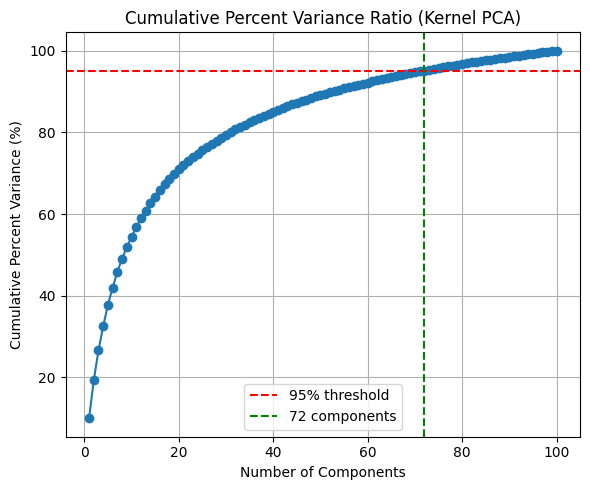

In [81]:
kpca = KernelPCA(n_components=100, kernel='rbf', gamma=0.01, random_state=0)
kpca.fit(X_scaled)
cpv_kpca = np.cumsum(kpca.eigenvalues_)/np.sum(kpca.eigenvalues_)*100
print(cpv_kpca)

# plot cumulative percent variance for kernel PCA
plt.figure(figsize=(6, 5))

# len(cpv_kpca) is 100, so we plot from 1 to 100 + 1 because range is exclusive at the end
plt.plot(range(1, len(cpv_kpca) + 1), cpv_kpca, marker='o')

# Find the number of components needed to reach 95% cumulative variance for kernel PCA
# n95 is the index of the first component where cpv_kpca >= 95, plus 1 because of zero-based indexing
# enumerate gives us pairs of (index, value) for cpv_kpca, and we check where the value is >= 95
n95 = next(i + 1 for i, v in enumerate(cpv_kpca) if v >= 95)

# Add horizontal and vertical lines to indicate the 95% threshold and the corresponding number of components for kernel PCA
plt.axhline(y=95, color='r', linestyle='--', label='95% threshold')
plt.axvline(x=n95, color='g', linestyle='--', label=f'{n95} components')

# Add text annotation to indicate the number of components needed for 95% variance for kernel PCA
plt.legend()
plt.title("Cumulative Percent Variance Ratio (Kernel PCA)")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Percent Variance (%)")

# Add grid for better readability
plt.grid()

# Use tight_layout to prevent overlap of labels and title
plt.tight_layout()
plt.show()

### Number of Principal Components Required:

1. For PCA, 40 components are needed to retain 95% CPV out of 64 total features.
2. For KPCA, 72 components are needed to retain 95% CPV out of the top 100 components computed from the RBF kernel space.

Note that CPV (cumulative percent variance) is the running total of variance as each principal component is added one by one. 

What I find interesting here is that the first principal component of PCA already accounts for 12.03% of the variance. This shows that it's the most important component in the digit data. In fact, we can also see that the first 10 components already account for about 60% of the total variance. Each additional component contributes less, until we reached the prescribed threshold of 95%.

For KPCA on the other hand, the variance is more spread out across the n=100 components. RBF kernel maps the data into a higher dimensional space where the variance is distributed more evenly, so it takes more components to reach the 95% CPV.

### Part 3. Classification with and without dimensionality reduction

In [82]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
print("Shape of X_train (training data):", X_train.shape)
print("Shape of y_train (training labels):", y_train.shape)
print("Shape of X_test (test data):", X_test.shape)
print("Shape of y_test (test labels):", y_test.shape)

Shape of X_train (training data): (1437, 64)
Shape of y_train (training labels): (1437,)
Shape of X_test (test data): (360, 64)
Shape of y_test (test labels): (360,)


3.1. Make a pipeline using StandardScaler, Kernel PCA (kernel = ‘sigmoid’,
n_components=40), and SVC (default hyper-parameters). Fit the pipeline on the training set, then report the accuracy and F1-score on the test set.

In [85]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kernel_pca', KernelPCA(n_components=40, kernel='sigmoid', random_state=0)),
    ('svc', SVC())
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
score = pipeline.score(X_test, y_test)
print("Test set accuracy:", score)
classification = classification_report(y_test, y_pred)
print("Classification Report:\n", classification)

Test set accuracy: 0.9916666666666667
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      1.00      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      0.97      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       1.00      1.00      1.00        36
           8       0.97      0.94      0.96        35
           9       1.00      1.00      1.00        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



3.2 Make a pipeline using StandardScaler, Linear Discriminant Analysis
(n_components=9), and SVC (default hyper-parameters). Fit the pipeline on the training set, then report the accuracy and F1-score on the test set.

In [93]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('Linear Discriminant Analysis', LinearDiscriminantAnalysis(n_components=9)),
    ('svc', SVC())
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
score = pipeline.score(X_test, y_test)
print("Test set accuracy:", score)
classification = classification_report(y_test, y_pred)
print("Classification Report:\n", classification)

Test set accuracy: 0.9722222222222222
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.85      0.97      0.91        36
           2       1.00      0.97      0.99        35
           3       0.97      0.97      0.97        37
           4       1.00      0.94      0.97        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.91      0.89      0.90        35
           9       1.00      1.00      1.00        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



 ### Can we extract more than 9 components from LDA? Why or why not?

Practically speaking, if we increase n_components to higher than 9, we will get the following error:

ValueError: n_components cannot be larger than min(n_features, n_classes - 1).

This is because for LDA, there are directions that maximize the ratio of between-class variance to within-class variance. These directions are the eigenvectors of the between-class scatter matrix. 

Since the digits dataset has 10 classes, the between-class scatter matrix has a rank of at most $10 - 1 = 9$, which means it can only produce 9 non-zero eigenvalues. There are only 9 non-zero eigenvalues to extract directions from. Any component beyond 9 would have 0 variance, meaning they have no useful discriminative information.

3.3 Make a pipeline using StandardScaler and SVC (default hyper-parameters)
alone. Fit the pipeline on the training set, then report the accuracy and F1-score on the test set. This is the case without any dimensionality reduction.

In [95]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
score = pipeline.score(X_test, y_test)
print("Test set accuracy:", score)
classification = classification_report(y_test, y_pred)
print("Classification Report:\n", classification)

Test set accuracy: 0.9861111111111112
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      0.97      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      0.97      0.99        37
           4       0.95      0.97      0.96        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       1.00      1.00      1.00        36
           8       0.97      0.94      0.96        35
           9       1.00      1.00      1.00        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



### Which of the three methods had the best test performance for classification? Explain.

| Method | Accuracy | Macro F1 |
|---|---|---|
| KPCA+SVC | 99.17% | 0.99 |
| Linear Discriminant Analysis + SVC | 97.22% | 0.97 |
| Standard Scaler + SVC | 98.61% | 0.99 |

The Standard Scaler, KPCA, and SVC pipeline performed the best with 99.17% accuracy and 0.99 macro F1 using only 40 components as opposed to the original 64 features. This also outpeformed even the case without dimensionality reduction (StandardScaler + SVC only). This shows that applying dimensionality reduction improved classification. 

The sigmoid kernel in KPCA maps the data into a higher-dimensional feature space where digit classes become more linearly separable. This likely captured nonlinear structure in the digit data that helped the SVC identify separate classes more cleanly.

Linear Discriminant Analysis with SVC performed the worst, presumably because it was constrained to only 9 components. This mathematical limitation could have discarded significant information from the original 64D space. Compared to the 40 components of PCA and the 72 components of KPCA, having only 9 components definitely reduced details that could have been identified by the SVC. Additionally, LDA finds projection directions that are linear combinations of the original 64 pixel features, so it could be less efficient when working with nonlinear geometry like handwritten digit data.